# Suicide rates and population size in Spain and the United States, 2001–2021

**Question:** do places (or years) with more inhabitants have higher or lower suicide *rates*?

**Rule of this notebook: we never compare raw numbers of suicides with population.** A larger region has more suicides simply because it has more people, so counts would always rise with population. Everything below uses **suicides per 100,000 inhabitants**, so a slope or correlation of zero means "population size makes no difference".

| Section | What it shows |
|---|---|
| 1. Data | One tidy table per country (region × year) with the rate computed in the same way everywhere |
| 2. National trends | Rate over time, and rate vs. population growth, both indexed to 2001 = 100 |
| 3. Regions in one period | Rate vs. population with uncertainty (error bars) and a fit; funnel plot to separate real differences from small-number noise |
| 4. Does it change over time? | Population–rate correlation computed year by year |
| 5. Regions over time | Heatmap of all rates, regions sorted by size; population growth vs. change in rate |
| 6. Summary | One table with the key numbers |

**Inputs** (in `data/processed/`): `usa_population.csv`, `usa_suicide_rate.csv`, `spain_population.csv`, `spain_suicide_rate.csv`.
**Outputs.** None: tables and figures are shown in the notebook.
**How to run.** Open the notebook from the `notebooks/` folder and use *Run All*. Paths are relative to the repository.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullLocator
from scipy.stats import spearmanr, chi2, norm

In [ ]:
from pathlib import Path

# Repository root: the first folder, going up from this notebook, that contains "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW = ROOT / "data" / "raw"              # original downloads (not uploaded to GitHub)
INTERIM = ROOT / "data" / "interim"      # large intermediate files (not uploaded to GitHub)
PROCESSED = ROOT / "data" / "processed"  # clean tables used in the analysis

## 1. Data

All rates are *crude* (no age adjustment) and computed by us as `suicides / population × 100,000`.
We do not use the `Age-Adjusted Death Rate` column of the US file because it only exists for the US and the file switches from crude to age-adjusted in 2014, which would break the comparison with Spain.

In [2]:
DATA = PROCESSED   # folder containing the four CSV files (data/processed)

PopUSA = pd.read_csv(f"{DATA}/usa_population.csv")        # population by state and year (U.S. Census Bureau)
SuiUSA = pd.read_csv(f"{DATA}/usa_suicide_rate.csv")      # suicide deaths by state and year (CDC)
PopESP = pd.read_csv(f"{DATA}/spain_population.csv")      # population by autonomous community and year
SuiESP = pd.read_csv(f"{DATA}/spain_suicide_rate.csv")    # suicide deaths by autonomous community and year (INE)

# The two Spanish files name some communities differently, so we match them by hand
ESP_NAMES = {
    "03 Asturias, Principado de": "Principado de Asturias", "04 Balears, Illes": "Illes Balears",
    "08 Castilla - La Mancha": "Castilla-La Mancha", "13 Madrid, Comunidad de": "Comunidad de Madrid",
    "14 Murcia, Región de": "Región de Murcia", "15 Navarra, Comunidad Foral de": "Comunidad Foral de Navarra",
    "17 Rioja, La": "La Rioja", "18 Ceuta": "Ciudad de Ceuta", "19 Melilla": "Ciudad de Melilla",
}
esp_name = lambda s: ESP_NAMES.get(s, s[3:])    # the rest only lose the "01 " prefix

# Same columns for both countries: year, region, suicides, population
usa = (SuiUSA.rename(columns={"Year": "year", "Location": "region", "Deaths": "suicides"})[["year", "region", "suicides"]]
       .merge(PopUSA.rename(columns={"region_name": "region"})[["year", "region", "population"]],
              on=["year", "region"], validate="1:1"))

esp = SuiESP.rename(columns={"Periodo": "year", "Total": "suicides"}).assign(
    region=lambda t: t["Comunidades y Ciudades Autónomas"].map(esp_name))[["year", "region", "suicides"]]
esp = esp.merge(PopESP.rename(columns={"region_name": "region"})[["year", "region", "population"]],
                on=["year", "region"], validate="1:1")

PANELS = {"United States": usa, "Spain": esp}
for name, p in PANELS.items():
    p["rate"] = p["suicides"] / p["population"] * 100_000          # suicides per 100,000 inhabitants
    print(f"{name:14s} {p['region'].nunique()} regions × {p['year'].nunique()} years = {len(p)} rows")

usa.head()

United States  51 regions × 21 years = 1071 rows
Spain          19 regions × 21 years = 399 rows


,year,region,suicides,population,rate
0,2001,Alabama,512,4467634,11.460205
1,2001,Alaska,102,633714,16.095589
2,2001,Arizona,767,5273477,14.544484
3,2001,Arkansas,382,2691571,14.192455
4,2001,California,2831,34479458,8.210686


## 2. National trends

For the whole country, population grows steadily year after year. Any rate that also drifts up or down would then "correlate" with population just because both depend on time, so a scatter of national rate vs. population would be misleading.
Instead we look at how both evolved relative to 2001 (index 2001 = 100).

In [3]:
BLUE, ORANGE, INK, INK2, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c3c2b7"
COLOR = {"United States": "#2a78d6", "Spain": "#7a3e9d"}

def style(ax):
    # Visible axes and no grid
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK)
        ax.spines[side].set_linewidth(1.5)
    ax.tick_params(colors=INK, width=1.5, length=6, labelsize=11)

def pop_formatter(v, _):
    return f"{v/1e6:g}M" if v >= 1e6 else f"{v/1e3:g}k"

# National totals per year
national = {}
for name, p in PANELS.items():
    n = p.groupby("year")[["suicides", "population"]].sum()
    n["rate"] = n["suicides"] / n["population"] * 100_000
    n["pop_index"] = n["population"] / n["population"].iloc[0] * 100
    n["rate_index"] = n["rate"] / n["rate"].iloc[0] * 100
    national[name] = n

display(pd.concat({k: v[["population", "suicides", "rate"]].round(2) for k, v in national.items()}, axis=1))

United States                      Spain               
        population suicides   rate population suicides  rate
year                                                        
2001     284968955    30622  10.75   40665545     3153  7.75
2002     287625193    31655  11.01   41035278     3329  8.11
2003     290107933    31484  10.85   41827838     3439  8.22
2004     292805298    32439  11.08   42547451     3483  8.19
2005     295516599    32637  11.04   43296338     3372  7.79
2006     298379912    33300  11.16   44009971     3211  7.30
2007     301231207    34598  11.49   44784666     3222  7.19
2008     304093966    36035  11.85   45668939     3420  7.49
2009     306771529    36909  12.03   46239273     3406  7.37
2010     309378227    38364  12.40   46486619     3131  6.74
2011     311839461    39518  12.67   46667174     3146  6.74
2012     314339099    40600  12.92   46818219     3498  7.47
2013     316726282    41149  12.99   46712650     3816  8.17
2014     319257560    42826  13.41   46495744     3863  8.31
2015     321815121    44193  13.73   46425722     3565  7.68
2016     324353340    44965  13.86   46418884     3535  7.62
2017     326608609    47173  14.44   46497393     3631  7.81
2018     328529577    48344  14.72   46645070     3504  7.51
2019     330226227    47511  14.39   46918951     3625  7.73
2020     331578104    45979  13.87   47318050     3914  8.27
2021     332100166    48183  14.51   47400798     3972  8.38

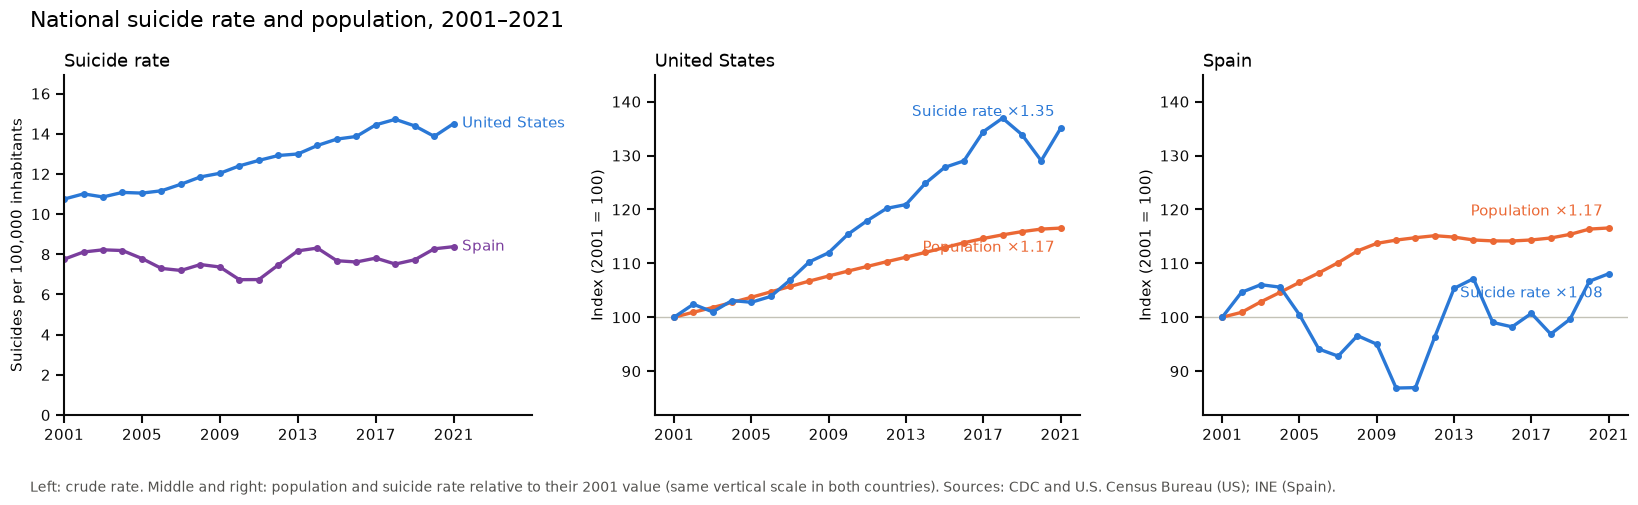

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.1, 1, 1], "wspace": 0.28})

# Left: national rate of both countries
ax = axes[0]
for name, n in national.items():
    ax.plot(n.index, n["rate"], color=COLOR[name], lw=2.4, marker="o", ms=4)
    ax.annotate(name, (n.index[-1], n["rate"].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color=COLOR[name], fontsize=11, va="center")
ax.set_ylim(0, max(n["rate"].max() for n in national.values()) * 1.15)
ax.set_xlim(2001, 2025)
ax.set_xticks(range(2001, 2022, 4))
ax.set_ylabel("Suicides per 100,000 inhabitants", fontsize=11)
ax.set_title("Suicide rate", fontsize=13, loc="left")
style(ax)

# Middle and right: population vs. rate, both indexed to 2001 = 100
for ax, (name, n) in zip(axes[1:], national.items()):
    ax.plot(n.index, n["pop_index"], color=ORANGE, lw=2.4, marker="o", ms=4)
    ax.plot(n.index, n["rate_index"], color=BLUE, lw=2.4, marker="o", ms=4)
    ax.axhline(100, color=GREY, lw=1, zorder=0)
    # The higher of the two end labels goes above its line and the lower one below, so they never overlap
    for col, color, text in [("pop_index", ORANGE, "Population"), ("rate_index", BLUE, "Suicide rate")]:
        other = "rate_index" if col == "pop_index" else "pop_index"
        above = n[col].iloc[-1] >= n[other].iloc[-1]
        ax.annotate(f"{text} ×{n[col].iloc[-1]/100:.2f}", (n.index[-1], n[col].iloc[-1]),
                    xytext=(-4, 9 if above else -17), textcoords="offset points", ha="right", color=color, fontsize=11)
    ax.set_xticks(range(2001, 2022, 4))
    ax.set_ylabel("Index (2001 = 100)", fontsize=11)
    ax.set_title(name, fontsize=13, loc="left")
    style(ax)
lo = min(min(n["pop_index"].min(), n["rate_index"].min()) for n in national.values())
hi = max(max(n["pop_index"].max(), n["rate_index"].max()) for n in national.values())
for ax in axes[1:]:
    ax.set_ylim(lo - 5, hi + 8)          # same scale in both countries so they can be compared

fig.suptitle("National suicide rate and population, 2001–2021", fontsize=16, x=0.04, ha="left")
fig.text(0.04, 0.01, "Left: crude rate. Middle and right: population and suicide rate relative to their 2001 value (same vertical scale in both countries). "
                     "Sources: CDC and U.S. Census Bureau (US); INE (Spain).", fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.85, left=0.06, right=0.98, bottom=0.17)
plt.show()

## 3. Regions in one period: does size matter?

Here the unit is the region (51 US states incl. DC, 19 Spanish autonomous communities), which removes the common time trend.

**Pooling years.** A single year has very few suicides in small regions (Ceuta and Melilla have between 0 and 6 per year), so their yearly rate jumps around by chance.
We pool a window of years: `rate = Σ suicides / Σ person-years × 100,000`. Set `PERIOD = (2021, 2021)` to use a single year.

**Uncertainty.** Suicides are rare events, so we treat the count as Poisson and draw an exact 95 % interval on each rate. Small regions get long error bars.

In [5]:
PERIOD = (2017, 2021)       # years pooled in sections 3 and 5 (first, last)

def poisson_ci(k, alpha=0.05):
    # Exact (Garwood) confidence interval for a Poisson count k
    k = np.asarray(k, dtype=float)
    lo = np.where(k > 0, chi2.ppf(alpha / 2, 2 * np.maximum(k, 1)) / 2, 0.0)
    hi = chi2.ppf(1 - alpha / 2, 2 * (k + 1)) / 2
    return lo, hi

def period_table(panel, y0, y1):
    # One row per region for the years y0..y1: pooled rate, mean population and exact 95 % interval
    w = panel[(panel["year"] >= y0) & (panel["year"] <= y1)]
    t = w.groupby("region").agg(suicides=("suicides", "sum"), person_years=("population", "sum"), pop=("population", "mean"))
    t["rate"] = t["suicides"] / t["person_years"] * 100_000
    lo, hi = poisson_ci(t["suicides"])
    t["rate_lo"], t["rate_hi"] = lo / t["person_years"] * 100_000, hi / t["person_years"] * 100_000
    return t

TABLES = {name: period_table(p, *PERIOD) for name, p in PANELS.items()}
for name, t in TABLES.items():
    print(f"{name}: {len(t)} regions, {int(t['suicides'].sum()):,} suicides in {PERIOD[0]}–{PERIOD[1]}")
display(TABLES["Spain"].sort_values("pop").round(2).head(5))

United States: 51 regions, 237,190 suicides in 2017–2021
Spain: 19 regions, 18,646 suicides in 2017–2021


,suicides,person_years,pop,rate,rate_lo,rate_hi
region,,,,,,
Ciudad de Ceuta,16,423992,84798.4,3.77,2.16,6.13
Ciudad de Melilla,12,431383,86276.6,2.78,1.44,4.86
La Rioja,128,1583140,316628.0,8.09,6.75,9.61
Cantabria,185,2912662,582532.4,6.35,5.47,7.34
Comunidad Foral de Navarra,237,3263151,652630.2,7.26,6.37,8.25


### 3a. Rate vs. population (with error bars and fit)

Dashed line: linear fit of the rate against log₁₀(population); bands: ±1 and ±2 standard deviations of the residuals.
The text gives the **Spearman correlation ρ** (rank-based, robust to the very different sizes of the regions) and the fitted change in rate for a **tenfold larger population**.
Zero means that size has no effect.

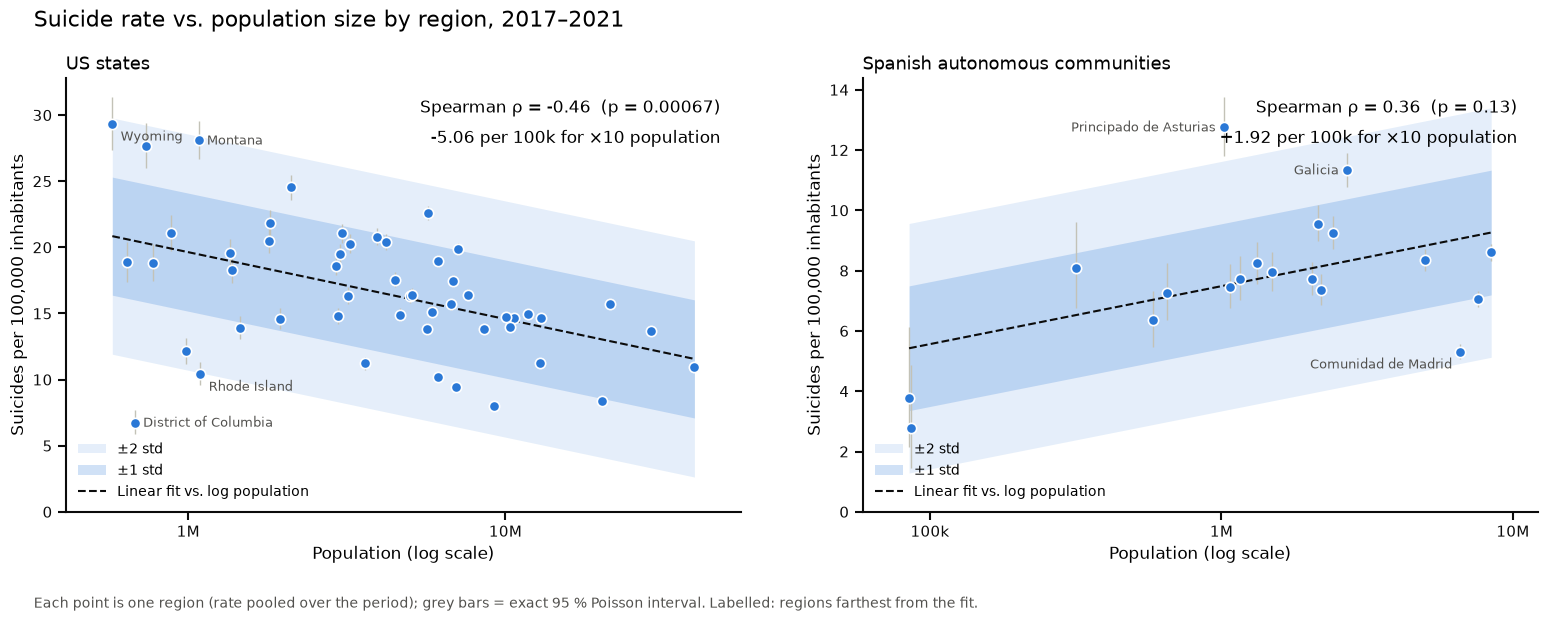

In [6]:
def region_stats(t):
    x, y = np.log10(t["pop"]), t["rate"]
    slope, intercept = np.polyfit(x, y, 1)                  # rate = intercept + slope · log10(population)
    resid = y - (intercept + slope * x)
    rho, p = spearmanr(t["pop"], y)
    return dict(slope=slope, intercept=intercept, std=resid.std(ddof=2), resid=resid, rho=rho, p=p)

def label_points(ax, t, idx, xcol, ycol, label_col=None):
    # Label the chosen points; labels on the right half of the plot go to the left of the point
    xmid = np.mean(ax.get_xlim()) if ax.get_xscale() == "linear" else np.sqrt(np.prod(ax.get_xlim()))
    for j, i in enumerate(idx):
        right = t.loc[i, xcol] > xmid
        ax.annotate(i if label_col is None else t.loc[i, label_col], (t.loc[i, xcol], t.loc[i, ycol]),
                    xytext=(-6 if right else 6, -3 - 9 * (j % 2)), textcoords="offset points",
                    ha="right" if right else "left", fontsize=9, color=INK2, zorder=6)

def scatter_panel(ax, t, title, n_labels=4):
    s = region_stats(t)
    ax.set_xscale("log")
    ax.margins(x=0.08)
    ax.errorbar(t["pop"], t["rate"], yerr=[t["rate"] - t["rate_lo"], t["rate_hi"] - t["rate"]],
                fmt="none", ecolor=GREY, elinewidth=1, zorder=2)
    x = np.logspace(np.log10(t["pop"].min()), np.log10(t["pop"].max()), 100)
    y = s["intercept"] + s["slope"] * np.log10(x)
    for k, alpha in [(2, 0.12), (1, 0.22)]:
        ax.fill_between(x, y - k * s["std"], y + k * s["std"], color=BLUE, alpha=alpha, lw=0, zorder=1, label=f"±{k} std")
    ax.plot(x, y, color=INK, lw=1.5, ls="--", zorder=3, label="Linear fit vs. log population")
    ax.scatter(t["pop"], t["rate"], s=55, color=BLUE, edgecolor="white", lw=1.2, zorder=4)
    ax.set_ylim(bottom=0)
    label_points(ax, t, s["resid"].abs().sort_values(ascending=False).index[:n_labels], "pop", "rate")
    ax.xaxis.set_major_formatter(FuncFormatter(pop_formatter)); ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Population (log scale)", fontsize=12)
    ax.set_ylabel("Suicides per 100,000 inhabitants", fontsize=12)
    ax.text(0.97, 0.95, f"Spearman ρ = {s['rho']:.2f}  (p = {s['p']:.2g})", transform=ax.transAxes, ha="right", va="top", fontsize=12)
    ax.text(0.97, 0.88, f"{s['slope']:+.2f} per 100k for ×10 population", transform=ax.transAxes, ha="right", va="top", fontsize=12)
    ax.legend(loc="lower left", frameon=False, fontsize=10)
    ax.set_title(title, fontsize=13, loc="left")
    style(ax)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
scatter_panel(axes[0], TABLES["United States"], "US states")
scatter_panel(axes[1], TABLES["Spain"], "Spanish autonomous communities", n_labels=3)
fig.suptitle(f"Suicide rate vs. population size by region, {PERIOD[0]}–{PERIOD[1]}", fontsize=16, x=0.04, ha="left")
fig.text(0.04, 0.01, "Each point is one region (rate pooled over the period); grey bars = exact 95 % Poisson interval. "
                     "Labelled: regions farthest from the fit.", fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.87, left=0.06, right=0.98, bottom=0.17, wspace=0.18)
plt.show()

VERSION ALTERNATIVA PLOTS

In [12]:

import plotly.graph_objects as go
from plotly.subplots import make_subplots

def interactive_scatter(t, title):
    s = region_stats(t)
    d = t.reset_index()

    fig = go.Figure()

    # Intervalos Poisson del 95 %
    fig.add_trace(go.Scatter(
        x=d["pop"],
        y=d["rate"],
        mode="markers",
        name="Regions",
        marker=dict(
            size=10,
            color="#2a78d6",
            line=dict(width=1.5, color="white")
        ),
        error_y=dict(
            type="data",
            symmetric=False,
            array=d["rate_hi"] - d["rate"],
            arrayminus=d["rate"] - d["rate_lo"],
            color="#aeb7c2",
            thickness=1,
            width=3
        ),
        customdata=d[["region", "suicides", "rate"]].values,
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "Population: %{x:,.0f}<br>"
            "Suicides: %{customdata[1]:,.0f}<br>"
            "Rate: %{y:.2f} per 100,000"
            "<extra></extra>"
        )
    ))

    # Regression line
    x = np.logspace(
        np.log10(t["pop"].min()),
        np.log10(t["pop"].max()),
        100
    )
    y = s["intercept"] + s["slope"] * np.log10(x)

    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode="lines",
        name="Linear fit",
        line=dict(color="#eb6834", width=2, dash="dash"),
        hoverinfo="skip"
    ))

    fig.update_layout(
        title=dict(
            text=f"{title}<br><sup>Spearman ρ = {s['rho']:.2f} "
                 f"| p = {s['p']:.3g}</sup>",
            x=0.02
        ),
        template="simple_white",
        height=570,
        hovermode="closest",
        font=dict(family="Arial", size=13),
        xaxis=dict(
            title="Population",
            type="log",
            showgrid=False,
            tickformat="~s"
        ),
        yaxis=dict(
            title="Suicides per 100,000 inhabitants",
            rangemode="tozero",
            showgrid=True,
            gridcolor="#eeeeee"
        ),
        legend=dict(
            orientation="h",
            y=-0.18,
            x=0
        ),
        margin=dict(l=75, r=35, t=100, b=90)
    )

    return fig


interactive_scatter(
    TABLES["United States"],
    "United States — 2017–2021"
).show()

interactive_scatter(
    TABLES["Spain"],
    "Spain — 2017–2021"
).show()


### 3b. Funnel plot: real differences or small-number noise?

The error bars above already hint at it: small regions have noisy rates. A **funnel plot** makes this explicit.
If every region had the same underlying rate (the national one), the observed rates would scatter around it only by chance, and the scatter would shrink as population grows, drawing a **funnel**.

- Dashed lines: 95 % limits; solid lines: 99.8 % limits (Poisson approximation of Wilson–Hilferty).
- A point **inside** the funnel is compatible with the national rate.
- A point **outside** differs from the national rate by more than chance.
- If the points are *wider* than the funnel at every size, the regions truly differ, but that is a different question from "does size matter" (that would be a tilted pattern, not a wide one).

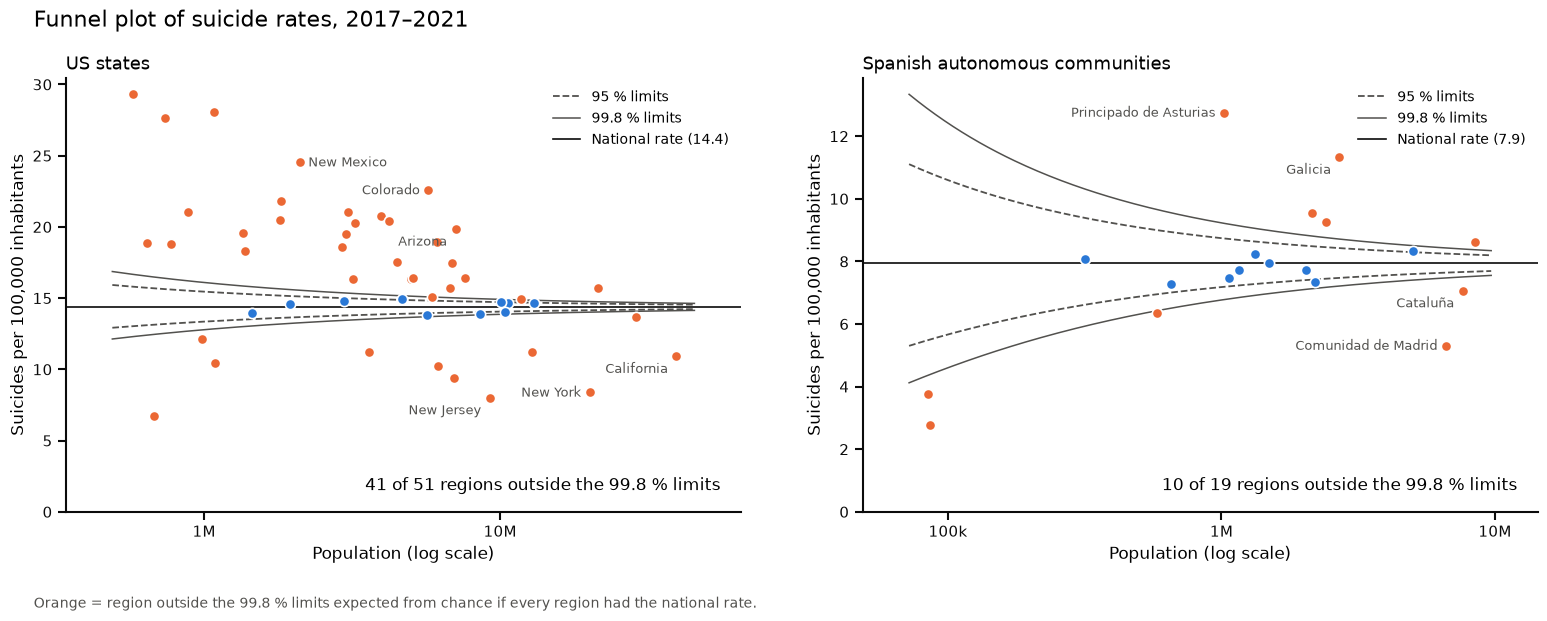

In [7]:
def funnel_limits(pop, p0, n_years, z):
    # Limits of the rate (per 100k) expected from chance alone, given the national rate p0 (per 100k)
    lam = p0 * pop * n_years / 100_000                      # expected number of suicides in the period
    base = 1 - 1 / (9 * lam) + z / (3 * np.sqrt(lam))
    return p0 * np.maximum(base, 0) ** 3

def funnel_panel(ax, t, title, n_years, n_labels=6):
    p0 = t["suicides"].sum() / t["person_years"].sum() * 100_000      # national rate over the period
    ax.set_xscale("log"); ax.margins(x=0.08)
    xs = np.logspace(np.log10(t["pop"].min() * 0.85), np.log10(t["pop"].max() * 1.15), 200)
    for z, ls, lw, lab in [(1.96, "--", 1.3, "95 % limits"), (3.09, "-", 1.1, "99.8 % limits")]:
        for sign in (+1, -1):
            ax.plot(xs, funnel_limits(xs, p0, n_years, sign * z), color=INK2, ls=ls, lw=lw, label=lab if sign == 1 else None, zorder=2)
    ax.axhline(p0, color=INK, lw=1.2, zorder=1, label=f"National rate ({p0:.1f})")

    up, dn = funnel_limits(t["pop"], p0, n_years, 3.09), funnel_limits(t["pop"], p0, n_years, -3.09)
    out = (t["rate"] > up) | (t["rate"] < dn)
    ax.scatter(t.loc[~out, "pop"], t.loc[~out, "rate"], s=55, color=BLUE, edgecolor="white", lw=1.2, zorder=4)
    ax.scatter(t.loc[out, "pop"], t.loc[out, "rate"], s=55, color=ORANGE, edgecolor="white", lw=1.2, zorder=5)
    dist = ((t["rate"] - p0) / (up - p0).clip(lower=1e-9)).abs()          # distance to the 99.8 % limit
    label_points(ax, t, dist[out].sort_values(ascending=False).index[:n_labels], "pop", "rate")

    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_formatter(FuncFormatter(pop_formatter)); ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Population (log scale)", fontsize=12)
    ax.set_ylabel("Suicides per 100,000 inhabitants", fontsize=12)
    ax.text(0.97, 0.05, f"{out.sum()} of {len(t)} regions outside the 99.8 % limits", transform=ax.transAxes, ha="right", fontsize=12)
    ax.legend(loc="upper right", frameon=False, fontsize=10)
    ax.set_title(title, fontsize=13, loc="left")
    style(ax)
    return int(out.sum())

n_years = PERIOD[1] - PERIOD[0] + 1
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
OUTSIDE = {}
OUTSIDE["United States"] = funnel_panel(axes[0], TABLES["United States"], "US states", n_years)
OUTSIDE["Spain"] = funnel_panel(axes[1], TABLES["Spain"], "Spanish autonomous communities", n_years, n_labels=4)
fig.suptitle(f"Funnel plot of suicide rates, {PERIOD[0]}–{PERIOD[1]}", fontsize=16, x=0.04, ha="left")
fig.text(0.04, 0.01, "Orange = region outside the 99.8 % limits expected from chance if every region had the national rate.",
         fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.87, left=0.06, right=0.98, bottom=0.17, wspace=0.18)
plt.show()

## 4. Does the relationship change over time?

Same question as 3a, but separately for every year: the Spearman correlation between a region's population and its suicide rate.
The shaded band is a 95 % interval (Fisher transform). Years are not pooled here, so rates of small regions are noisy and the band is wide, especially for Spain (19 regions).
A band that contains 0 means that the data do not show any relationship between size and rate that year.

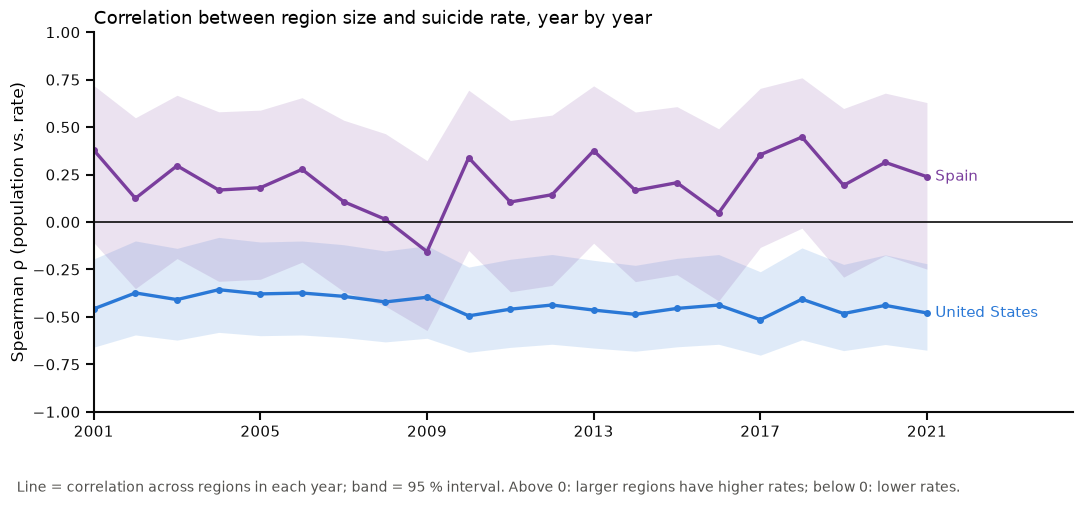

In [8]:
rows = []
for name, p in PANELS.items():
    for year, g in p.groupby("year"):
        n = len(g)
        rho, pv = spearmanr(g["population"], g["rate"])
        se = np.sqrt((1 + rho ** 2 / 2) / (n - 3))                     # standard error of atanh(rho) for Spearman
        lo, hi = np.tanh(np.arctanh(rho) + np.array([-1.96, 1.96]) * se)
        rows.append(dict(country=name, year=year, rho=rho, p=pv, lo=lo, hi=hi))
rho_year = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(11, 5.2))
for name in PANELS:
    r = rho_year[rho_year["country"] == name]
    ax.fill_between(r["year"], r["lo"], r["hi"], color=COLOR[name], alpha=0.15, lw=0)
    ax.plot(r["year"], r["rho"], color=COLOR[name], lw=2.4, marker="o", ms=4)
    ax.annotate(name, (r["year"].iloc[-1], r["rho"].iloc[-1]), xytext=(6, 0), textcoords="offset points", color=COLOR[name], fontsize=11, va="center")
ax.axhline(0, color=INK, lw=1.2)
ax.set_xlim(2001, 2024.5); ax.set_xticks(range(2001, 2022, 4)); ax.set_ylim(-1, 1)
ax.set_ylabel("Spearman ρ (population vs. rate)", fontsize=12)
ax.set_title("Correlation between region size and suicide rate, year by year", fontsize=13, loc="left")
style(ax)
fig.text(0.01, 0.01, "Line = correlation across regions in each year; band = 95 % interval. Above 0: larger regions have higher rates; below 0: lower rates.",
         fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(left=0.08, right=0.97, top=0.9, bottom=0.17)
plt.show()

## 5. Regions over time

### 5a. Heatmap of all rates

Every row is a region, sorted by population (largest on top), every column a year, and the colour is the suicide rate.
If size mattered, the top and the bottom of the heatmap would have different colours; vertical changes show differences between regions, horizontal changes show time trends.
Note that the colour scale is different in each country.

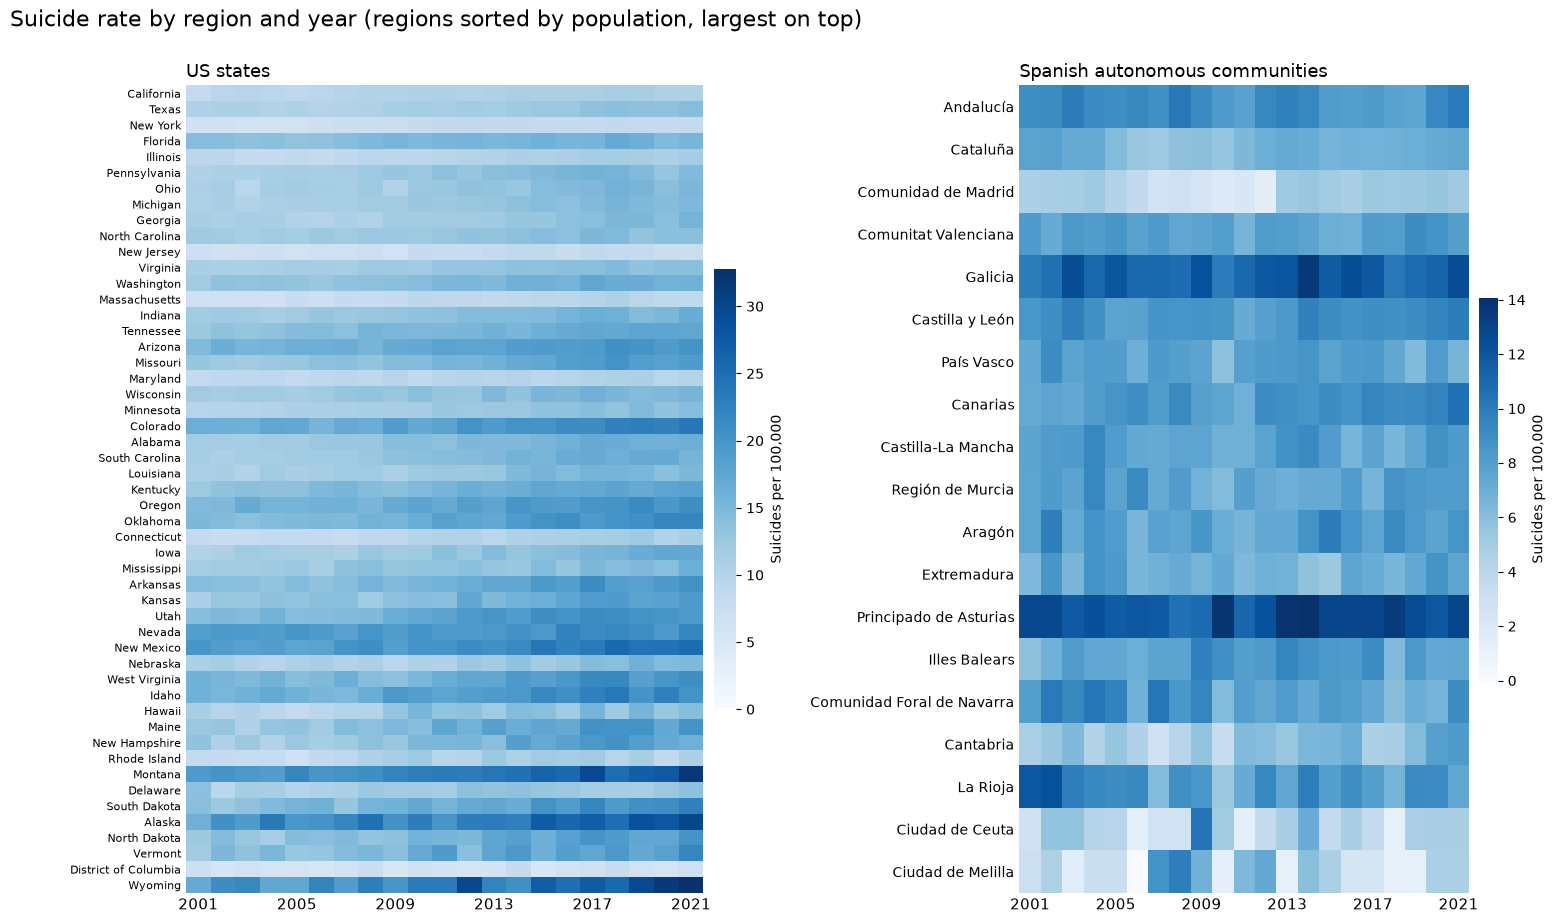

In [9]:
def heatmap_panel(fig, ax, p, title, fontsize):
    order = p.groupby("region")["population"].mean().sort_values(ascending=False).index       # largest first
    m = p.pivot(index="region", columns="year", values="rate").loc[order]
    im = ax.imshow(m.values, aspect="auto", cmap="Blues", vmin=0, interpolation="nearest")
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index, fontsize=fontsize)
    ax.set_xticks(range(0, m.shape[1], 4)); ax.set_xticklabels(m.columns[::4], fontsize=11)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(title, fontsize=13, loc="left")
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label("Suicides per 100,000", fontsize=10); cb.outline.set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(16, 9.5), gridspec_kw={"width_ratios": [1.15, 1]})
heatmap_panel(fig, axes[0], usa, "US states", 8)
heatmap_panel(fig, axes[1], esp, "Spanish autonomous communities", 10)
fig.suptitle("Suicide rate by region and year (regions sorted by population, largest on top)", fontsize=16, x=0.04, ha="left")
fig.subplots_adjust(top=0.9, left=0.15, right=0.97, bottom=0.05, wspace=0.55)
plt.show()

### 5b. Regions that grew more: did their suicide rate change more?

The previous sections ask about *size*. Here we ask about *growth*: we compare an early period with a late one and plot, for every region, the **percentage change in population** against the **change in the suicide rate**.
Both periods are pooled over three years to reduce noise.

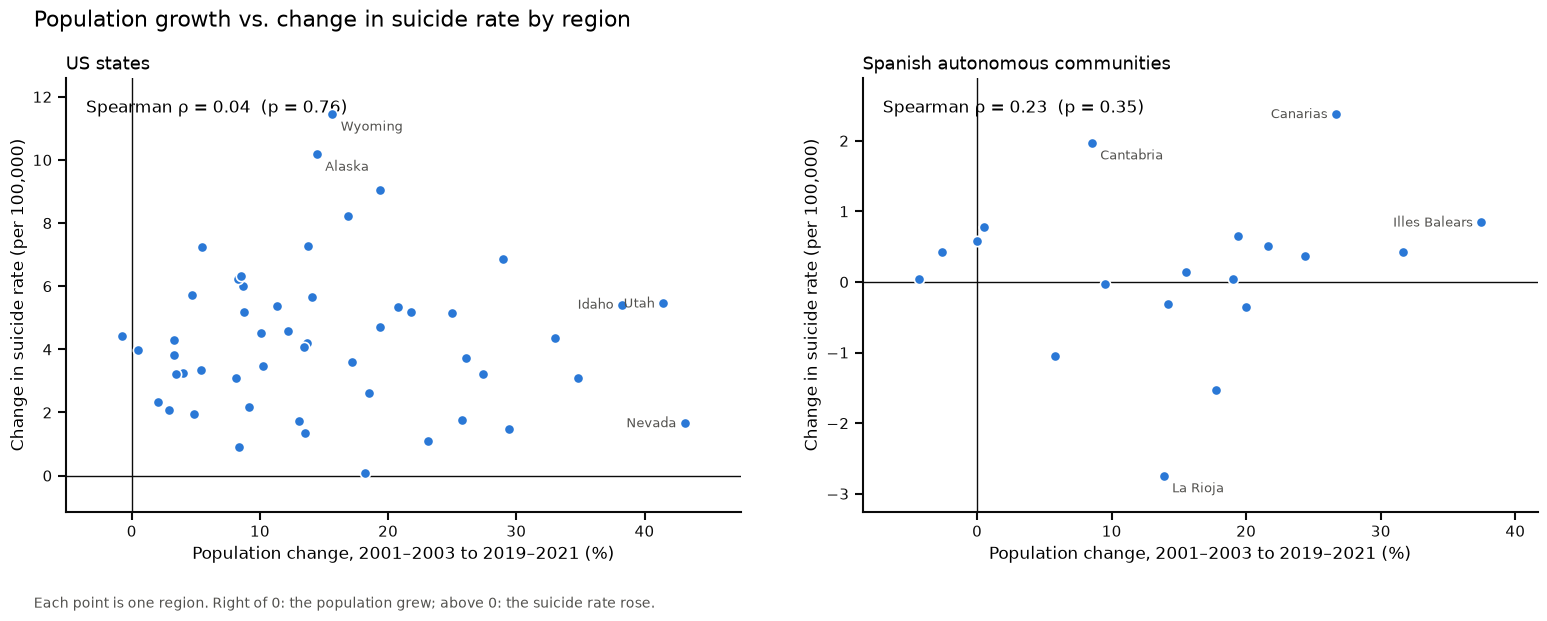

In [10]:
EARLY, LATE = (2001, 2003), (2019, 2021)

def growth_table(panel):
    e, l = period_table(panel, *EARLY), period_table(panel, *LATE)
    g = pd.DataFrame({"pop_growth_pct": (l["pop"] / e["pop"] - 1) * 100, "rate_change": l["rate"] - e["rate"], "pop": l["pop"]})
    return g

def growth_panel(ax, g, title, n_labels=5):
    rho, p = spearmanr(g["pop_growth_pct"], g["rate_change"])
    ax.axhline(0, color=INK, lw=1); ax.axvline(0, color=INK, lw=1)
    ax.scatter(g["pop_growth_pct"], g["rate_change"], s=55, color=BLUE, edgecolor="white", lw=1.2, zorder=4)
    z = ((g["pop_growth_pct"] - g["pop_growth_pct"].mean()) / g["pop_growth_pct"].std()).abs() + \
        ((g["rate_change"] - g["rate_change"].mean()) / g["rate_change"].std()).abs()
    ax.margins(0.1)
    label_points(ax, g, z.sort_values(ascending=False).index[:n_labels], "pop_growth_pct", "rate_change")
    ax.set_xlabel(f"Population change, {EARLY[0]}–{EARLY[1]} to {LATE[0]}–{LATE[1]} (%)", fontsize=12)
    ax.set_ylabel("Change in suicide rate (per 100,000)", fontsize=12)
    ax.text(0.03, 0.95, f"Spearman ρ = {rho:.2f}  (p = {p:.2g})", transform=ax.transAxes, va="top", fontsize=12)
    ax.set_title(title, fontsize=13, loc="left")
    style(ax)
    return rho, p

GROWTH = {name: growth_table(p) for name, p in PANELS.items()}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
GROWTH_RHO = {}
GROWTH_RHO["United States"] = growth_panel(axes[0], GROWTH["United States"], "US states")
GROWTH_RHO["Spain"] = growth_panel(axes[1], GROWTH["Spain"], "Spanish autonomous communities", n_labels=4)
fig.suptitle("Population growth vs. change in suicide rate by region", fontsize=16, x=0.04, ha="left")
fig.text(0.04, 0.01, "Each point is one region. Right of 0: the population grew; above 0: the suicide rate rose.",
         fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.87, left=0.06, right=0.98, bottom=0.17, wspace=0.18)
plt.show()

## 6. Summary

In [11]:
rows = []
for name in PANELS:
    t, s = TABLES[name], region_stats(TABLES[name])
    rows.append({
        "country": name,
        "regions": len(t),
        f"national rate {PERIOD[0]}–{PERIOD[1]} (per 100k)": round(t["suicides"].sum() / t["person_years"].sum() * 1e5, 2),
        "Spearman ρ (size vs. rate)": round(s["rho"], 2),
        "p-value": float(f"{s['p']:.2g}"),
        "rate change per ×10 population": round(s["slope"], 2),
        "regions outside funnel (99.8 %)": f"{OUTSIDE[name]} of {len(t)}",
        "ρ (pop. growth vs. rate change)": round(GROWTH_RHO[name][0], 2),
    })
pd.DataFrame(rows).set_index("country").T

country,United States,Spain
regions,51,19
national rate 2017–2021 (per 100k),14.38,7.94
Spearman ρ (size vs. rate),-0.46,0.36
p-value,0.00067,0.13
rate change per ×10 population,-5.06,1.92
regions outside funnel (99.8 %),41 of 51,10 of 19
ρ (pop. growth vs. rate change),0.04,0.23


**Limitations.** Rates are crude, so differences in age structure between regions (and between countries) are not removed.
With only 19 Spanish regions the correlations have wide uncertainty, and a correlation across regions is not a statement about individual people.
Small regions also get few suicides per year; that is why we pool years and show Poisson uncertainty.